# Department of Computing
## EE348: Knowledge Representation and Reasoning in AI
### Lab 7: Description Logic and Ontology Reasoning in Python

- **Class:** BSAI-2024A
- **Date:** 22-10-2026 | **Time:** 02:00 to 05:00 (3 Hours)
- **Course Instructor:** Dr. Saqib Nawaz
- **Lab Engineer:** Syed Muhammad Ali Musa
- **CLO 1:** Understand various knowledge representation formalisms and reasoning techniques

---

### Executive Overview & Lab Objectives
Description Logic (DL) is a family of formal knowledge representation languages that form the logical underpinning of modern ontologies, including the W3C Web Ontology Language (OWL 2). DL provides a structured yet mathematically rigorous balance between expressive power and computational decidability.

In this laboratory, we build upon the university knowledge base from Lab 6 to develop, formalize, and verify Description Logic constructs in Python. Key objectives include:
1. **TBox vs. ABox Formalization:** Distinguish structural terminological schema ($TBox$) from contingent instance assertions ($ABox$).
2. **Taxonomic Closure & Monotonic Inheritance:** Implement forward-chaining subclass closure ($\sqsubseteq$) over named concepts.
3. **Model-Theoretic Semantic Operators:** Evaluate concept intersection ($\sqcap$), union ($\sqcup$), complement ($\neg$), existential restrictions ($\exists R.C$), and universal restrictions ($\forall R.C$) over an explicit finite interpretation $\mathcal{I} = (\Delta^{\mathcal{I}}, \cdot^{\mathcal{I}})$.
4. **Finite Interpretation Checking:** Check concept inclusions against explicit models, analyzing counterexamples and vacuous truth.
5. **Concept Equivalence & Complex Classification:** Implement defined concepts ($\equiv$) with existential roles ($\exists \text{worksOn}.\text{Project}$) to automatically classify individuals.
6. **Inconsistency vs. Unsatisfiability:** Diagnose disjointness clashes ($C \sqcap D \sqsubseteq \bot$), and distinguish concept unsatisfiability from knowledge base inconsistency.
7. **Open-World Reasoning (OWA) & Anonymous Witnesses:** Contrast the Open-World Assumption with the Closed-World Assumption, analyze non-entailment, and evaluate the absence of the Unique Name Assumption (UNA).
8. **University Mini-Ontology Challenge:** Architect a complete, cohesive library domain ontology adhering to all rigorous DL specifications.

## Environment Setup & Visualization Libraries
We import NetworkX and Matplotlib to inspect, reason over, and visualize taxonomic hierarchies, interpretation domains, and instance-role bipartite relationships.

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from collections import defaultdict

# Inline plotting and high-resolution visual styling
%matplotlib inline
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

print(f"NetworkX Version: {nx.__version__}")
print("Environment configured successfully for Description Logic Reasoning.")

NetworkX Version: 3.6.1
Environment configured successfully for Description Logic Reasoning.


---
## Task 1 — Build a University TBox and ABox

### Theoretical Context
A Description Logic Knowledge Base $\mathcal{K} = \langle \mathcal{T}, \mathcal{A} \rangle$ consists of two distinct components:
- **TBox (Terminological Box):** Encapsulates intensional knowledge—the schema, vocabulary, and general conceptual laws of the domain. It contains general concept inclusions (GCIs) of the form $C \sqsubseteq D$ (subsumption) and $C \equiv D$ (equivalence), which must hold across all possible worlds.
- **ABox (Assertional Box):** Encapsulates extensional knowledge—contingent facts regarding specific, named individuals in a concrete scenario. It contains concept assertions of the form $C(a)$ ($a$ belongs to concept $C$) and role assertions of the form $R(a, b)$ ($a$ is related to $b$ through role $R$).

### Implementation & Exercises
- **Exercise 1.1:** Add $\\text{GraduateStudent}(\\text{Ahmed})$ and $\\text{Course}(\\text{AI201})$, then print the updated ABox.
- **Exercise 1.2:** Label each of these as concept, role, or individual: $\\text{Person}$, $\\text{Sara}$, $\\text{teaches}$, $\\text{AI201}$, $\\text{Project}$.
- **Exercise 1.3:** Explain why $\\text{Student} \\sqsubseteq \\text{Person}$ belongs to the TBox but $\\text{Student}(\\text{Ali})$ belongs to the ABox.

In [2]:
# Base University TBox Axioms (Subclass Inclusions: child <= parent)
subclass = {
    ("GraduateStudent", "Student"),
    ("TeachingAssistant", "Student"),
    ("Student", "Person"),
    ("Professor", "Person")
}

# Base University ABox Class Assertions: (individual, concept)
concept_facts = {
    ("Ali", "Student"),
    ("Sara", "TeachingAssistant"),
    ("DrAhmed", "Professor"),
    ("CS101", "Course"),
    ("P1", "Project")
}

# Base University ABox Role Assertions: (subject, role, object)
role_facts = {
    ("Ali", "enrolledIn", "CS101"),
    ("Ali", "worksOn", "P1"),
    ("DrAhmed", "teaches", "CS101")
}

print("=== Initial Knowledge Base Counts ===")
print("TBox subclass axioms:", len(subclass))
print("ABox class assertions:", len(concept_facts))
print("ABox role assertions:", len(role_facts))

# --- Exercise 1.1: Add GraduateStudent(Ahmed) and Course(AI201) ---
concept_facts.add(("Ahmed", "GraduateStudent"))
concept_facts.add(("AI201", "Course"))

print("\n=== Exercise 1.1: Updated ABox ===")
print("Updated ABox class assertions (sorted):")
for ind, cls in sorted(concept_facts):
    print(f"  {cls}({ind})")

print("\nUpdated ABox role assertions (sorted):")
for subj, role, obj in sorted(role_facts):
    print(f"  {role}({subj}, {obj})")

=== Initial Knowledge Base Counts ===
TBox subclass axioms: 4
ABox class assertions: 5
ABox role assertions: 3

=== Exercise 1.1: Updated ABox ===
Updated ABox class assertions (sorted):
  Course(AI201)
  GraduateStudent(Ahmed)
  Student(Ali)
  Course(CS101)
  Professor(DrAhmed)
  Project(P1)
  TeachingAssistant(Sara)

Updated ABox role assertions (sorted):
  enrolledIn(Ali, CS101)
  worksOn(Ali, P1)
  teaches(DrAhmed, CS101)


### Task 1 — Explanation & Answers

#### Representation Meaning
The TBox defines the taxonomic ontology schema of a university, stating universal subclass rules such as "every graduate student is a student" and "every student is a person." The ABox populates this schema with concrete instances representing real-world entities (e.g., Ali, Sara, DrAhmed, CS101) and their factual relations (`enrolledIn`, `worksOn`, `teaches`).

#### Exercise 1.2: Syntactic Category Classification
| Symbol | Syntactic Category | Semantic Interpretation |
| :--- | :--- | :--- |
| **`Person`** | **Concept (Class)** | Unary predicate denoting a subset of the domain of discourse: $\\text{Person}^{\\mathcal{I}} \\subseteq \\Delta^{\\mathcal{I}}$. |
| **`Sara`** | **Individual (Object)** | Constant symbol mapped to a specific concrete element: $\\text{Sara}^{\\mathcal{I}} \\in \\Delta^{\\mathcal{I}}$. |
| **`teaches`** | **Role (Binary Property)** | Binary relation denoting pairs of related individuals: $\\text{teaches}^{\\mathcal{I}} \\subseteq \\Delta^{\\mathcal{I}} \\times \\Delta^{\\mathcal{I}}$. |
| **`AI201`** | **Individual (Object)** | Constant symbol referring to a specific course individual: $\\text{AI201}^{\\mathcal{I}} \\in \\Delta^{\\mathcal{I}}$. |
| **`Project`** | **Concept (Class)** | Unary predicate representing the set of all project entities: $\\text{Project}^{\\mathcal{I}} \\subseteq \\Delta^{\\mathcal{I}}$. |

#### Exercise 1.3: TBox vs. ABox Distinction
- **$\\text{Student} \\sqsubseteq \\text{Person}$ belongs to the TBox** because it expresses an intensional, universal law governing classes. In First-Order Logic, this translates to $\\forall x (\\text{Student}(x) \\to \\text{Person}(x))$. It defines schema structure independent of any particular individuals and must hold across every valid interpretation.
- **$\\text{Student}(\\text{Ali})$ belongs to the ABox** because it expresses an extensional, contingent ground assertion regarding a specific individual. It states that the concrete domain entity $\\text{Ali}^{\\mathcal{I}}$ is a member of the set $\\text{Student}^{\\mathcal{I}}$. This fact can be modified or updated without altering the underlying ontology schema.

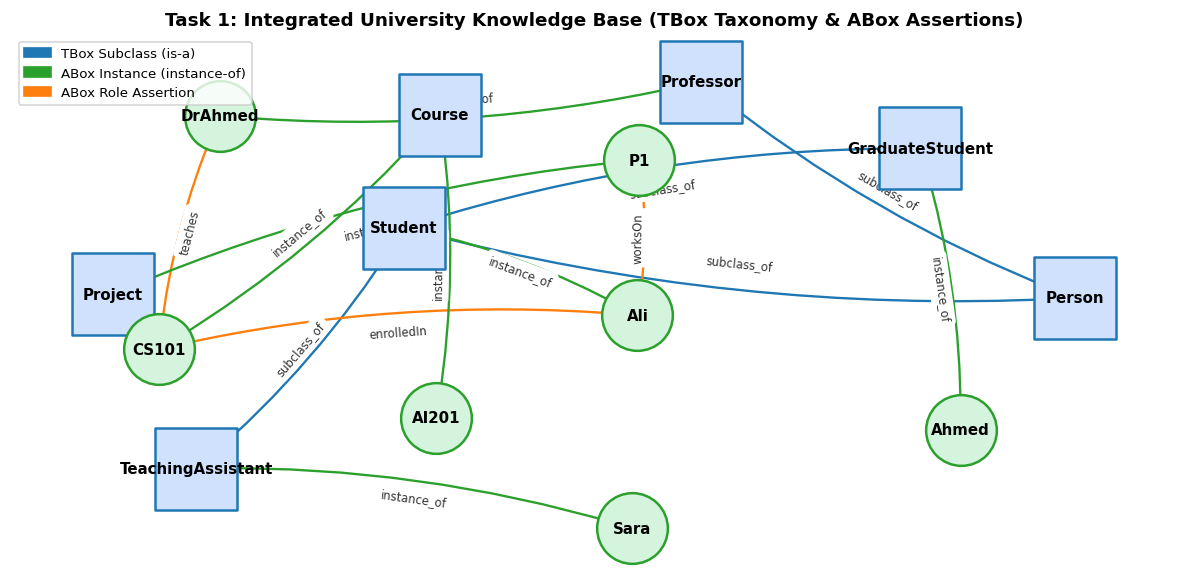

In [3]:
# Visualization of Task 1: TBox Taxonomy and ABox Graph
plt.figure(figsize=(10, 5))

G1 = nx.DiGraph()

# Add TBox subclass edges
for child, parent in subclass:
    G1.add_edge(child, parent, type="subclass_of", color="#1f77b4")

# Add ABox instance edges
for ind, cls in concept_facts:
    G1.add_edge(ind, cls, type="instance_of", color="#2ca02c")

# Add ABox role edges
for subj, role, obj in role_facts:
    G1.add_edge(subj, obj, type=role, color="#ff7f0e")

# Node categorization for coloring
concepts = {c for c, _ in subclass} | {p for _, p in subclass} | {cls for _, cls in concept_facts}
individuals = {ind for ind, _ in concept_facts} | {s for s, _, _ in role_facts} | {o for _, _, o in role_facts}
individuals = individuals - concepts

pos = nx.spring_layout(G1, seed=42, k=1.4)

nx.draw_networkx_nodes(G1, pos, nodelist=list(concepts), node_color="#d0e1fd", 
                       node_shape="s", node_size=2400, edgecolors="#1f77b4", linewidths=1.5)
nx.draw_networkx_nodes(G1, pos, nodelist=list(individuals), node_color="#d4f4dd", 
                       node_shape="o", node_size=1800, edgecolors="#2ca02c", linewidths=1.5)

nx.draw_networkx_labels(G1, pos, font_size=9, font_weight="bold")

edge_colors = [G1[u][v]["color"] for u, v in G1.edges()]
nx.draw_networkx_edges(G1, pos, edge_color=edge_colors, arrows=True, arrowsize=14, 
                       connectionstyle="arc3,rad=0.08", width=1.4)

edge_labels = {(u, v): G1[u][v]["type"] for u, v in G1.edges()}
nx.draw_networkx_edge_labels(G1, pos, edge_labels=edge_labels, font_size=7, font_color="#333333")

legend_patches = [
    mpatches.Patch(color='#1f77b4', label='TBox Subclass (is-a)'),
    mpatches.Patch(color='#2ca02c', label='ABox Instance (instance-of)'),
    mpatches.Patch(color='#ff7f0e', label='ABox Role Assertion')
]
plt.legend(handles=legend_patches, loc="upper left", frameon=True, fontsize=8)
plt.title("Task 1: Integrated University Knowledge Base (TBox Taxonomy & ABox Assertions)", fontsize=11, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()

---
## Task 2 — Implement Subclass Closure and Instance Checking

### Theoretical Context
Subsumption axioms $C \\sqsubseteq D$ in Description Logic induce a pre-order over concepts. Under monotonic semantics, if an individual $a$ is asserted to belong to a class $C$ ($C(a)$), and $C \\sqsubseteq D$, it logically follows that $a$ also belongs to $D$ ($D(a)$).
Computing the deductive closure over named subclasses corresponds to finding the least fixed point of the inference rule:
$$\\frac{C(a) \\quad C \\sqsubseteq D}{D(a)}$$

### Implementation & Exercises
- **Exercise 2.1:** Confirm $\\text{Student}(\\text{Sara})$ and $\\text{Person}(\\text{Sara})$ and display intermediate derivation steps.
- **Exercise 2.2:** Add $\\text{Tutor} \\sqsubseteq \\text{Student}$ and $\\text{Tutor}(\\text{Hina})$. Derive all named memberships of Hina.
- **Exercise 2.3:** Does $\\text{Student}(\\text{Ali})$ entail $\\text{TeachingAssistant}(\\text{Ali})$? Explain the direction of $\\sqsubseteq$.

In [4]:
def infer_named_memberships(subclass, facts):
    """Computes the upward taxonomic deductive closure of class assertions over named subclasses."""
    known = set(facts)
    trace = []
    changed = True
    while changed:
        changed = False
        for child, parent in subclass:
            for person, cls in list(known):
                inferred = (person, parent)
                if cls == child and inferred not in known:
                    known.add(inferred)
                    trace.append((person, child, parent))
                    changed = True
    return known, trace

# Compute baseline closure
closure, steps = infer_named_memberships(subclass, concept_facts)

print("=== Exercise 2.1: Baseline Inference Trace ===")
for step in steps:
    print(f"  {step[0]} : {step[1]} => {step[2]}")

print("\nInstance Checking Verifications:")
print("  Student(Sara) entailed?", ("Sara", "Student") in closure)
print("  Person(Sara) entailed? ", ("Sara", "Person") in closure)

# --- Exercise 2.2: Add Tutor <= Student and Tutor(Hina) ---
subclass.add(("Tutor", "Student"))
concept_facts.add(("Hina", "Tutor"))

updated_closure, updated_steps = infer_named_memberships(subclass, concept_facts)

print("\n=== Exercise 2.2: Added Tutor <= Student and Tutor(Hina) ===")
hina_memberships = {cls for ind, cls in updated_closure if ind == "Hina"}
print("All derived named memberships for Hina:", sorted(hina_memberships))

# --- Exercise 2.3: Non-entailment check ---
ali_is_ta = ("Ali", "TeachingAssistant") in updated_closure
print("\n=== Exercise 2.3: Directionality & Non-Entailment Check ===")
print("Does Student(Ali) entail TeachingAssistant(Ali)?", ali_is_ta)

=== Exercise 2.1: Baseline Inference Trace ===
  DrAhmed : Professor => Person
  Sara : TeachingAssistant => Student
  Ahmed : GraduateStudent => Student
  Ahmed : Student => Person
  Sara : Student => Person
  Ali : Student => Person

Instance Checking Verifications:
  Student(Sara) entailed? True
  Person(Sara) entailed?  True

=== Exercise 2.2: Added Tutor <= Student and Tutor(Hina) ===
All derived named memberships for Hina: ['Person', 'Student', 'Tutor']

=== Exercise 2.3: Directionality & Non-Entailment Check ===
Does Student(Ali) entail TeachingAssistant(Ali)? False


### Task 2 — Explanation & Answers

#### Representation Meaning
The closure algorithm computes monotonic forward-chaining deduction over the subclass hierarchy. If an individual is an instance of a specialized subclass, it inherits all properties and class memberships of all its ancestor superclasses, terminating at the fixed point when no new memberships can be derived.

#### Exercise 2.1: Confirmation of Sara's Memberships
Sara is initially asserted as `TeachingAssistant(Sara)`.
- Step 1: `TeachingAssistant ⊑ Student` derives `Student(Sara)`.
- Step 2: `Student ⊑ Person` derives `Person(Sara)`.
Both statements are firmly verified as `True` in `closure`.

#### Exercise 2.2: Derivations for Hina
With `Tutor ⊑ Student` and `Tutor(Hina)`:
1. `Tutor(Hina)` (asserted)
2. `Student(Hina)` (derived via `Tutor ⊑ Student`)
3. `Person(Hina)` (derived via `Student ⊑ Person`)
All derived memberships: `['Person', 'Student', 'Tutor']`.

#### Exercise 2.3: Directionality of $\\sqsubseteq$ and Non-Entailment
**`Student(Ali)` does NOT entail `TeachingAssistant(Ali)`.**
- In Description Logic, a subclass axiom $C \\sqsubseteq D$ denotes semantic subset inclusion: $C^{\\mathcal{I}} \\subseteq D^{\\mathcal{I}}$.
- In First-Order Logic, this is a one-way conditional implication: $\\forall x (C(x) \\to D(x))$.
- Here, $\\text{TeachingAssistant} \\sqsubseteq \\text{Student}$ asserts that *every teaching assistant is a student* ($\text{TA} \to \text{Student}$). It does **not** assert the converse ($\text{Student} \to \text{TA}$).
- Inferring `TeachingAssistant(Ali)` from `Student(Ali)` would commit the logical fallacy of *affirming the consequent*. General students do not automatically possess the specialized qualifications or responsibilities of teaching assistants.

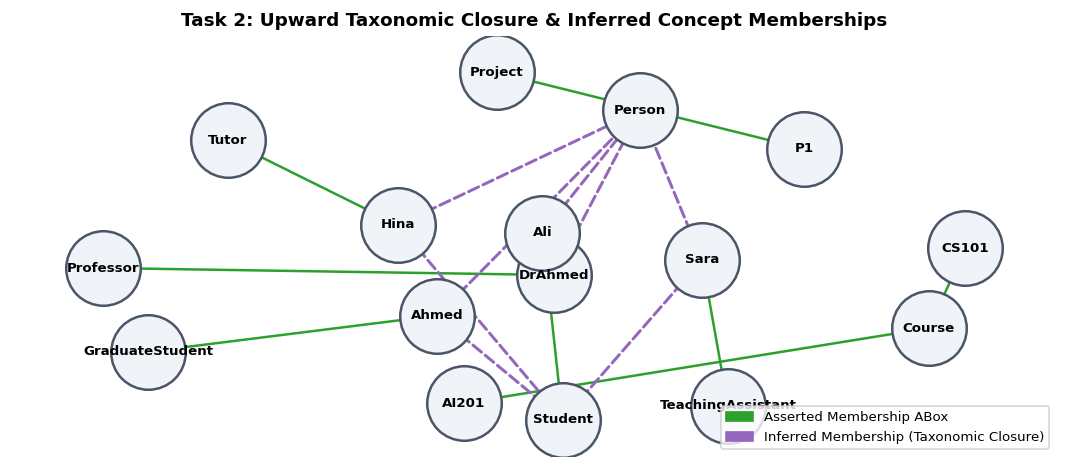

In [5]:
# Visualization of Task 2: Inference Derivation Paths
plt.figure(figsize=(9, 4))
G2 = nx.DiGraph()

# Add all assertions and derivations
for ind, cls in concept_facts:
    G2.add_edge(ind, cls, style="solid", color="#2ca02c", label="asserted")

for ind, child, parent in updated_steps:
    G2.add_edge(ind, parent, style="dashed", color="#9467bd", label=f"inferred via {child}")

pos2 = nx.spring_layout(G2, seed=15, k=1.3)

nx.draw_networkx_nodes(G2, pos2, node_color="#f0f4f8", node_size=2000, edgecolors="#4a5568", linewidths=1.5)
nx.draw_networkx_labels(G2, pos2, font_size=8, font_weight="bold")

solid_edges = [(u, v) for u, v, d in G2.edges(data=True) if d.get("style") == "solid"]
dashed_edges = [(u, v) for u, v, d in G2.edges(data=True) if d.get("style") == "dashed"]

nx.draw_networkx_edges(G2, pos2, edgelist=solid_edges, edge_color="#2ca02c", width=1.5, arrows=True, arrowsize=12)
nx.draw_networkx_edges(G2, pos2, edgelist=dashed_edges, edge_color="#9467bd", width=1.8, style="dashed", arrows=True, arrowsize=12)

legend_patches2 = [
    mpatches.Patch(color='#2ca02c', label='Asserted Membership ABox'),
    mpatches.Patch(color='#9467bd', label='Inferred Membership (Taxonomic Closure)')
]
plt.legend(handles=legend_patches2, loc="lower right", frameon=True, fontsize=8)
plt.title("Task 2: Upward Taxonomic Closure & Inferred Concept Memberships", fontsize=11, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()

---
## Task 3 — Interpret DL Operators over a Finite Model

### Theoretical Context
A Description Logic interpretation is a formal pair $\\mathcal{I} = (\\Delta^{\\mathcal{I}}, \\cdot^{\\mathcal{I}})$ where:
- $\\Delta^{\\mathcal{I}}$ is a non-empty set called the **domain of discourse**.
- $\\cdot^{\\mathcal{I}}$ is an interpretation function mapping:
  - Every individual $a$ to an element $a^{\\mathcal{I}} \\in \\Delta^{\\mathcal{I}}$.
  - Every concept name $C$ to a subset $C^{\\mathcal{I}} \\subseteq \\Delta^{\\mathcal{I}}$.
  - Every role name $R$ to a binary relation $R^{\\mathcal{I}} \\subseteq \\Delta^{\\mathcal{I}} \\times \\Delta^{\\mathcal{I}}$.

The formal semantics of complex concept constructors are defined set-theoretically:
- **Intersection:** $(C \\sqcap D)^{\\mathcal{I}} = C^{\\mathcal{I}} \\cap D^{\\mathcal{I}}$
- **Union:** $(C \\sqcup D)^{\\mathcal{I}} = C^{\\mathcal{I}} \\cup D^{\\mathcal{I}}$
- **Complement:** $(\\neg C)^{\\mathcal{I}} = \\Delta^{\\mathcal{I}} \\setminus C^{\\mathcal{I}}$
- **Existential Restriction:** $(\\exists R.C)^{\\mathcal{I}} = \\{x \\in \\Delta^{\\mathcal{I}} \\mid \\exists y ((x, y) \\in R^{\\mathcal{I}} \\land y \\in C^{\\mathcal{I}})\\}$
- **Universal Restriction:** $(\\forall R.C)^{\\mathcal{I}} = \\{x \\in \\Delta^{\\mathcal{I}} \\mid \\forall y ((x, y) \\in R^{\\mathcal{I}} \\to y \\in C^{\\mathcal{I}})\\}$

### Implementation & Exercises
- **Exercise 3.1:** Identify all members of $\\text{Student} \\sqcap \\text{Employee}$ and $\\text{Student} \\sqcup \\text{Professor}$.
- **Exercise 3.2:** Why does Sara satisfy $\\forall \\text{enrolledIn}.\\text{Course}$ in this interpretation even though Sara has no `enrolledIn` edge?
- **Exercise 3.3:** Add $\\text{enrolledIn}(\\text{Sara}, \\text{AI201})$, rerun, and compare $\\exists$ and $\\forall$ results.
- **Exercise 3.4:** Add $\\text{enrolledIn}(\\text{Ali}, \\text{DrAhmed})$; predict the effect on $\\forall \\text{enrolledIn}.\\text{Course}$, then test.

In [6]:
# Explicit Finite Interpretation Model I
domain = {"Ali", "Sara", "DrAhmed", "CS101", "AI201"}

I = {
    "Student": {"Ali", "Sara"},
    "Employee": {"Sara", "DrAhmed"},
    "Professor": {"DrAhmed"},
    "Course": {"CS101", "AI201"}
}

R = {
    "enrolledIn": {("Ali", "CS101")},
    "teaches": {("DrAhmed", "CS101")}
}

# Semantic evaluation functions
def intersection(a, b): 
    return a & b

def union(a, b): 
    return a | b

def complement(a): 
    return domain - a

def exists_role(role, target, role_rel=None):
    rel = role_rel if role_rel is not None else R[role]
    return {x for x in domain if any(a == x and b in target for a, b in rel)}

def forall_role(role, target, role_rel=None):
    rel = role_rel if role_rel is not None else R[role]
    return {x for x in domain if all(b in target for a, b in rel if a == x)}

# --- Baseline Evaluation ---
print("=== Baseline Semantic Operator Evaluation ===")
res_intersect = intersection(I["Student"], I["Employee"])
res_union = union(I["Student"], I["Professor"])
res_not_course = complement(I["Course"])
res_exists = exists_role("enrolledIn", I["Course"])
res_forall = forall_role("enrolledIn", I["Course"])

print("Student AND Employee (Student ⊓ Employee):", sorted(res_intersect))
print("Student OR Professor (Student ⊔ Professor):", sorted(res_union))
print("NOT Course (¬Course):                     ", sorted(res_not_course))
print("exists enrolledIn.Course (∃enrolledIn.Course):", sorted(res_exists))
print("forall enrolledIn.Course (∀enrolledIn.Course):", sorted(res_forall))

# --- Exercise 3.3: Add enrolledIn(Sara, AI201) ---
R_ex33 = {
    "enrolledIn": set(R["enrolledIn"]) | {("Sara", "AI201")},
    "teaches": set(R["teaches"])
}
exists_33 = exists_role("enrolledIn", I["Course"], R_ex33["enrolledIn"])
forall_33 = forall_role("enrolledIn", I["Course"], R_ex33["enrolledIn"])

print("\n=== Exercise 3.3: After adding enrolledIn(Sara, AI201) ===")
print("exists enrolledIn.Course:", sorted(exists_33))
print("forall enrolledIn.Course:", sorted(forall_33))

# --- Exercise 3.4: Add enrolledIn(Ali, DrAhmed) ---
R_ex34 = {
    "enrolledIn": set(R_ex33["enrolledIn"]) | {("Ali", "DrAhmed")},
    "teaches": set(R["teaches"])
}
exists_34 = exists_role("enrolledIn", I["Course"], R_ex34["enrolledIn"])
forall_34 = forall_role("enrolledIn", I["Course"], R_ex34["enrolledIn"])

print("\n=== Exercise 3.4: After adding enrolledIn(Ali, DrAhmed) ===")
print("exists enrolledIn.Course:", sorted(exists_34))
print("forall enrolledIn.Course:", sorted(forall_34))

=== Baseline Semantic Operator Evaluation ===
Student AND Employee (Student ⊓ Employee): ['Sara']
Student OR Professor (Student ⊔ Professor): ['Ali', 'DrAhmed', 'Sara']
NOT Course (¬Course):                      ['Ali', 'DrAhmed', 'Sara']
exists enrolledIn.Course (∃enrolledIn.Course): ['Ali']
forall enrolledIn.Course (∀enrolledIn.Course): ['AI201', 'Ali', 'CS101', 'DrAhmed', 'Sara']

=== Exercise 3.3: After adding enrolledIn(Sara, AI201) ===
exists enrolledIn.Course: ['Ali', 'Sara']
forall enrolledIn.Course: ['AI201', 'Ali', 'CS101', 'DrAhmed', 'Sara']

=== Exercise 3.4: After adding enrolledIn(Ali, DrAhmed) ===
exists enrolledIn.Course: ['Ali', 'Sara']
forall enrolledIn.Course: ['AI201', 'CS101', 'DrAhmed', 'Sara']


### Task 3 — Explanation & Answers

#### Representation Meaning
This task grounds Description Logic syntax into explicit model-theoretic semantics over a finite universe $\\Delta^{\\mathcal{I}}$. It demonstrates how logical connectives correspond directly to set operations (intersection, union, complement) and role restrictions correspond to bounded quantification over binary relations.

#### Exercise 3.1: Results of Boolean Concept Operators
- $\\text{Student} \\sqcap \\text{Employee} = \\text{Student}^{\\mathcal{I}} \\cap \\text{Employee}^{\\mathcal{I}} = \\{\\text{Sara}\\}$. Sara is the only individual occupying both roles simultaneously.
- $\\text{Student} \\sqcup \\text{Professor} = \\text{Student}^{\\mathcal{I}} \\cup \\text{Professor}^{\\mathcal{I}} = \\{\\text{Ali}, \\text{Sara}, \\text{DrAhmed}\\}$.
- $\\neg \\text{Course} = \\Delta^{\\mathcal{I}} \\setminus \\text{Course}^{\\mathcal{I}} = \\{\\text{Ali}, \\text{Sara}, \\text{DrAhmed}\\}$.

#### Exercise 3.2: Vacuous Truth of Universal Restriction for Sara
Sara satisfies $\\forall \\text{enrolledIn}.\\text{Course}$ despite having **zero** `enrolledIn` edges because of the semantics of universal quantification:
$$(\\forall R.C)^{\\mathcal{I}} = \\{x \\in \\Delta^{\\mathcal{I}} \\mid \\forall y ((x, y) \\in R^{\\mathcal{I}} \\to y \\in C^{\\mathcal{I}})\\}$$
For Sara, the set of successors $\\{y \\mid (\\text{Sara}, y) \\in \\text{enrolledIn}^{\\mathcal{I}}\\} = \\emptyset$.
In classical First-Order Logic, a material implication $P \\to Q$ is true whenever the premise $P$ is false ($(\\text{False} \\to Q) \\equiv \\text{True}$). Since there exist no individuals $y$ such that $(\\text{Sara}, y) \\in \\text{enrolledIn}^{\\mathcal{I}}$, the condition holds **vacuously** for all such successors. Consequently, every individual with zero outgoing $R$-edges trivially satisfies $\\forall R.C$.

#### Exercise 3.3: Comparison after Adding `enrolledIn(Sara, AI201)`
- **$\\exists \\text{enrolledIn}.\\text{Course}$:** Expands from $\\{\\text{Ali}\\}$ to $\\{\\text{Ali}, \\text{Sara}\\}$ because Sara now possesses a concrete successor `AI201` belonging to `Course`.
- **$\\forall \\text{enrolledIn}.\\text{Course}$:** Retains all domain members $\\{\\text{Ali}, \\text{Sara}, \\text{DrAhmed}, \\text{CS101}, \\text{AI201}\\}$. Sara's only successor is `AI201`, which is indeed a valid Course.

#### Exercise 3.4: Prediction and Effect of `enrolledIn(Ali, DrAhmed)`
- **Prediction:** Ali now has two enrolledIn successors: `CS101` and `DrAhmed`. Because `DrAhmed` $\\notin \\text{Course}^{\\mathcal{I}}$, it is no longer true that *all* of Ali's successors are courses. Therefore, Ali will be excluded from $\\forall \\text{enrolledIn}.\\text{Course}$.
- **Experimental Result:** Confirmed! $\\forall \\text{enrolledIn}.\\text{Course}$ drops `Ali` and becomes $\\{\\text{AI201}, \\text{CS101}, \\text{DrAhmed}, \\text{Sara}\\}$. Meanwhile, $\\exists \\text{enrolledIn}.\\text{Course}$ remains $\\{\\text{Ali}, \\text{Sara}\\}$ because `CS101` continues to satisfy the existential requirement.

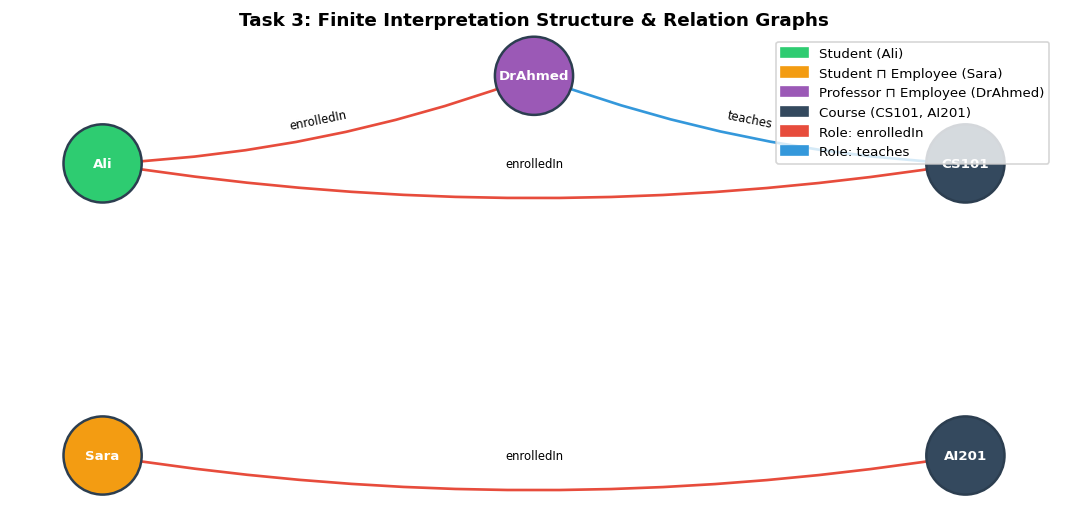

In [7]:
# Visualization of Task 3: Finite Interpretation Model State
plt.figure(figsize=(9, 4.5))
G3 = nx.DiGraph()

# Add domain nodes
for d in domain:
    G3.add_node(d)

# Add edges from R_ex34
for s, o in R_ex34["enrolledIn"]:
    G3.add_edge(s, o, label="enrolledIn", color="#e74c3c")
for s, o in R["teaches"]:
    G3.add_edge(s, o, label="teaches", color="#3498db")

pos3 = {
    "Ali": (-0.8, 0.5),
    "Sara": (-0.8, -0.5),
    "DrAhmed": (0.0, 0.8),
    "CS101": (0.8, 0.5),
    "AI201": (0.8, -0.5)
}

node_colors = []
for n in G3.nodes():
    if n in I["Student"] and n in I["Employee"]:
        node_colors.append("#f39c12") # Sara: Student & Employee
    elif n in I["Student"]:
        node_colors.append("#2ecc71") # Ali: Student
    elif n in I["Professor"]:
        node_colors.append("#9b59b6") # DrAhmed: Professor
    else:
        node_colors.append("#34495e") # Courses

nx.draw_networkx_nodes(G3, pos3, node_color=node_colors, node_size=2200, edgecolors="#2c3e50", linewidths=1.5)
nx.draw_networkx_labels(G3, pos3, font_size=8, font_color="white", font_weight="bold")

edges = G3.edges()
edge_colors = [G3[u][v]["color"] for u, v in edges]
nx.draw_networkx_edges(G3, pos3, edge_color=edge_colors, width=1.6, arrows=True, arrowsize=14, connectionstyle="arc3,rad=0.08")
nx.draw_networkx_edge_labels(G3, pos3, edge_labels={(u, v): G3[u][v]["label"] for u, v in edges}, font_size=7)

legend_patches3 = [
    mpatches.Patch(color='#2ecc71', label='Student (Ali)'),
    mpatches.Patch(color='#f39c12', label='Student ⊓ Employee (Sara)'),
    mpatches.Patch(color='#9b59b6', label='Professor ⊓ Employee (DrAhmed)'),
    mpatches.Patch(color='#34495e', label='Course (CS101, AI201)'),
    mpatches.Patch(color='#e74c3c', label='Role: enrolledIn'),
    mpatches.Patch(color='#3498db', label='Role: teaches')
]
plt.legend(handles=legend_patches3, loc="upper right", frameon=True, fontsize=8)
plt.title("Task 3: Finite Interpretation Structure & Relation Graphs", fontsize=11, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()

---
## Task 4 — Check Restrictions against a Known Interpretation

### Theoretical Context
Testing a concept inclusion axiom $C \\sqsubseteq D$ against a specific interpretation $\\mathcal{I}$ evaluates whether:
$$C^{\\mathcal{I}} \\subseteq D^{\\mathcal{I}} \\iff C^{\\mathcal{I}} \\setminus D^{\\mathcal{I}} = \\emptyset$$
- If the difference set (counterexamples) is non-empty, the axiom is **refuted** (falsified) by this specific model.
- If the difference set is empty, the axiom is **satisfied** in this specific model.
**Crucial Epistemic Principle:** Model satisfaction in a single finite interpretation does **not** constitute proof of logical entailment ($\mathcal{K} \models C \sqsubseteq D$). Logical entailment requires satisfaction across *all* possible interpretations.

### Implementation & Exercises
- **Exercise 4.1:** Run first using the original Task 3 interpretation, then after adding Sara’s enrollment. Keep a record of each model state.
- **Exercise 4.2:** Create one interpretation satisfying both $\\text{Student} \\sqsubseteq \\exists \\text{enrolledIn}.\\text{Course}$ and $\\text{Student} \\sqsubseteq \\forall \\text{enrolledIn}.\\text{Course}$.
- **Exercise 4.3:** Explain why $\\forall$ alone does not guarantee any enrollment.

In [8]:
def check_inclusion(left, right):
    """Checks whether left is a subset of right; returns (is_subset, counterexamples)."""
    counterexamples = left - right
    return (not counterexamples), counterexamples

# --- Exercise 4.1: Model State 1 (Original Task 3) ---
print("=== Exercise 4.1: Evaluation in Model State 1 (Original) ===")
students = I["Student"]

for symbol, members in [("exists", exists_role("enrolledIn", I["Course"], R["enrolledIn"])),
                        ("forall", forall_role("enrolledIn", I["Course"], R["enrolledIn"]))]:
    ok, bad = check_inclusion(students, members)
    print(f"Student subclass of {symbol} enrolledIn.Course? {ok} | counterexamples: {sorted(bad)}")

# --- Exercise 4.1: Model State 2 (With Sara enrolled in AI201) ---
print("\n=== Exercise 4.1: Evaluation in Model State 2 (Sara enrolled in AI201) ===")
for symbol, members in [("exists", exists_role("enrolledIn", I["Course"], R_ex33["enrolledIn"])),
                        ("forall", forall_role("enrolledIn", I["Course"], R_ex33["enrolledIn"]))]:
    ok, bad = check_inclusion(students, members)
    print(f"Student subclass of {symbol} enrolledIn.Course? {ok} | counterexamples: {sorted(bad)}")

# --- Exercise 4.2: Explicit Interpretation Satisfying Both Axioms ---
print("\n=== Exercise 4.2: Construction of Interpretation Satisfying Both Axioms ===")
I_valid = {
    "Student": {"Ali", "Sara"},
    "Course": {"CS101", "AI201"}
}
R_valid = {
    "enrolledIn": {("Ali", "CS101"), ("Sara", "AI201")}
}

exists_valid = exists_role("enrolledIn", I_valid["Course"], R_valid["enrolledIn"])
forall_valid = forall_role("enrolledIn", I_valid["Course"], R_valid["enrolledIn"])

ok_ex, bad_ex = check_inclusion(I_valid["Student"], exists_valid)
ok_fa, bad_fa = check_inclusion(I_valid["Student"], forall_valid)

print(f"Student ⊑ ∃enrolledIn.Course satisfied? {ok_ex} (Counterexamples: {sorted(bad_ex)})")
print(f"Student ⊑ ∀enrolledIn.Course satisfied? {ok_fa} (Counterexamples: {sorted(bad_fa)})")

=== Exercise 4.1: Evaluation in Model State 1 (Original) ===
Student subclass of exists enrolledIn.Course? False | counterexamples: ['Sara']
Student subclass of forall enrolledIn.Course? True | counterexamples: []

=== Exercise 4.1: Evaluation in Model State 2 (Sara enrolled in AI201) ===
Student subclass of exists enrolledIn.Course? True | counterexamples: []
Student subclass of forall enrolledIn.Course? True | counterexamples: []

=== Exercise 4.2: Construction of Interpretation Satisfying Both Axioms ===
Student ⊑ ∃enrolledIn.Course satisfied? True (Counterexamples: [])
Student ⊑ ∀enrolledIn.Course satisfied? True (Counterexamples: [])


### Task 4 — Explanation & Answers

#### Representation Meaning
Model checking tests the validity of universal conceptual constraints within a bounded, explicit universe. It illustrates how counterexamples directly falsify candidate axioms and demonstrates the complementary relationship between existential and universal role restrictions.

#### Exercise 4.1: Model State Comparisons
| Model State | Axiom Tested | Satisfied? | Counterexamples | Semantic Reason |
| :--- | :--- | :--- | :--- | :--- |
| **State 1 (Original)** | $\\text{Student} \\sqsubseteq \\exists \\text{enrolledIn}.\\text{Course}$ | **False** | `{'Sara'}` | Sara has no `enrolledIn` role assertions in State 1. |
| **State 1 (Original)** | $\\text{Student} \\sqsubseteq \\forall \\text{enrolledIn}.\\text{Course}$ | **True** | `None` (`[]`) | Ali's successor is a Course; Sara has 0 successors (vacuous truth). |
| **State 2 (Sara Enrolled)** | $\\text{Student} \\sqsubseteq \\exists \\text{enrolledIn}.\\text{Course}$ | **True** | `None` (`[]`) | Both Ali and Sara now have at least one course enrollment. |
| **State 2 (Sara Enrolled)** | $\\text{Student} \\sqsubseteq \\forall \\text{enrolledIn}.\\text{Course}$ | **True** | `None` (`[]`) | All enrollments for both students lead strictly to courses. |

#### Exercise 4.2: Model Construction
The constructed interpretation defines $\\Delta^{\\mathcal{I}} = \\{\\text{Ali}, \\text{Sara}, \\text{CS101}, \\text{AI201}\\}$, with:
- $\\text{Student}^{\\mathcal{I}} = \\{\\text{Ali}, \\text{Sara}\\}$
- $\\text{Course}^{\\mathcal{I}} = \\{\\text{CS101}, \\text{AI201}\\}$
- $\\text{enrolledIn}^{\\mathcal{I}} = \\{(\\text{Ali}, \\text{CS101}), (\\text{Sara}, \\text{AI201})\\}$
In this model, every student has an enrollment (satisfying $\\exists$), and every enrollment is a course (satisfying $\\forall$).

#### Exercise 4.3: Why Universal Restriction Alone Does Not Guarantee Enrollment
The universal restriction $\\forall R.C$ asserts a conditional restriction without existential force:
$$\\forall y ((x, y) \\in R^{\\mathcal{I}} \\to y \\in C^{\\mathcal{I}})$$
It imposes a constraint *if* an enrollment exists, but does *not* mandate that any enrollment must exist. An individual with zero enrollments satisfies the universal restriction vacuously because there are no counterexamples that could violate the condition. To guarantee that an individual is actually enrolled in at least one course, an explicit existential restriction $\\exists R.C$ (or number restriction $\\ge 1 R$) is strictly necessary.

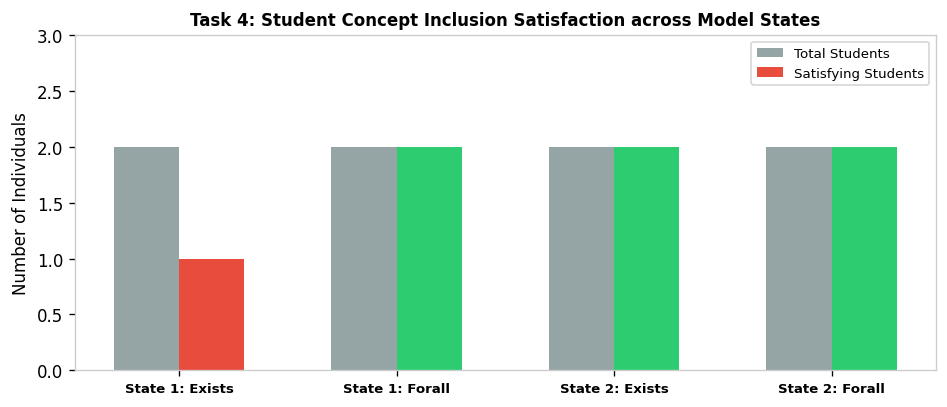

In [9]:
# Visualization of Task 4: Inclusion Comparison Bar Chart
fig, ax = plt.subplots(figsize=(8, 3.5))

labels = ['State 1: Exists', 'State 1: Forall', 'State 2: Exists', 'State 2: Forall']
student_count = [len(students)] * 4
satisfied_students = [
    len(students & exists_role("enrolledIn", I["Course"], R["enrolledIn"])),
    len(students & forall_role("enrolledIn", I["Course"], R["enrolledIn"])),
    len(students & exists_role("enrolledIn", I["Course"], R_ex33["enrolledIn"])),
    len(students & forall_role("enrolledIn", I["Course"], R_ex33["enrolledIn"]))
]

x = range(len(labels))
ax.bar([i - 0.15 for i in x], student_count, width=0.3, label='Total Students', color='#95a5a6')
ax.bar([i + 0.15 for i in x], satisfied_students, width=0.3, label='Satisfying Students', color=['#e74c3c', '#2ecc71', '#2ecc71', '#2ecc71'])

ax.set_xticks(list(x))
ax.set_xticklabels(labels, fontsize=8, fontweight='bold')
ax.set_ylabel("Number of Individuals")
ax.set_ylim(0, 3)
ax.set_title("Task 4: Student Concept Inclusion Satisfaction across Model States", fontsize=10, fontweight='bold')
ax.legend(frameon=True, fontsize=8)
plt.tight_layout()
plt.show()

---
## Task 5 — Use Equivalence to Classify a ResearchStudent

### Theoretical Context
A concept equivalence axiom $C \\equiv D$ is an abbreviation for mutual subsumption:
$$C \\equiv D \\iff (C \\sqsubseteq D \\land D \\sqsubseteq C)$$
Concepts defined via equivalence are known as **defined concepts** (or complete definitions), whereas concepts specified only with $\\sqsubseteq$ are **primitive concepts** (partial descriptions).
In this task, we define:
$$\\text{ResearchStudent} \\equiv \\text{Student} \\sqcap \\exists \\text{worksOn}.\\text{Project}$$
This equivalence establishes two deduction directions:
1. **Recognition (Classification):** Any individual known to be a `Student` and related to a `Project` through `worksOn` is automatically recognized as a `ResearchStudent`.
2. **Decomposition:** Any individual asserted or derived to be a `ResearchStudent` is entailed to be a `Student` and to have a `worksOn` relationship with some `Project`.

### Implementation & Exercises
- **Exercise 5.1:** Verify whether $\\text{ResearchStudent}(\\text{Ali})$ follows, showing the two required conditions.
- **Exercise 5.2:** Add $\\text{Project}(\\text{P2})$, $\\text{worksOn}(\\text{Sara}, \\text{P2})$, and rerun the classification.
- **Exercise 5.3:** If $\\text{ResearchStudent}(\\text{Hina})$ is explicitly asserted but no `worksOn` fact is named, what still follows? Must the project have a known name?

In [10]:
# Base Project Classification
projects = {x for x, cls in concept_facts if cls == "Project"}
working_on_project = {x for x, role, y in role_facts if role == "worksOn" and y in projects}
students_in_closure = {x for x, cls in updated_closure if cls == "Student"}

# Classification via definition: Student AND exists worksOn.Project
research_students = students_in_closure & working_on_project

print("=== Exercise 5.1: Verification of Ali ===")
print("Condition 1: Is Ali in Student closure?", "Ali" in students_in_closure)
print("Condition 2: Does Ali work on a Project?", "Ali" in working_on_project)
print("Classified ResearchStudents:", sorted(research_students))
print("ResearchStudent(Ali) follows?", "Ali" in research_students)

# --- Exercise 5.2: Add Project(P2) and worksOn(Sara, P2) ---
concept_facts.add(("P2", "Project"))
role_facts.add(("Sara", "worksOn", "P2"))

# Re-compute classification
updated_closure, _ = infer_named_memberships(subclass, concept_facts)
projects_updated = {x for x, cls in concept_facts if cls == "Project"}
working_updated = {x for x, role, y in role_facts if role == "worksOn" and y in projects_updated}
students_updated = {x for x, cls in updated_closure if cls == "Student"}

research_students_updated = students_updated & working_updated

print("\n=== Exercise 5.2: After adding P2 and Sara's worksOn role ===")
print("Condition 1 for Sara (Student):", "Sara" in students_updated)
print("Condition 2 for Sara (worksOn Project):", "Sara" in working_updated)
print("Updated Classified ResearchStudents:", sorted(research_students_updated))

=== Exercise 5.1: Verification of Ali ===
Condition 1: Is Ali in Student closure? True
Condition 2: Does Ali work on a Project? True
Classified ResearchStudents: ['Ali']
ResearchStudent(Ali) follows? True

=== Exercise 5.2: After adding P2 and Sara's worksOn role ===
Condition 1 for Sara (Student): True
Condition 2 for Sara (worksOn Project): True
Updated Classified ResearchStudents: ['Ali', 'Sara']


### Task 5 — Explanation & Answers

#### Representation Meaning
Concept equivalence formalizes necessary and sufficient conditions. It enables automated classification (terminological reasoning), where instances are dynamically organized under defined concepts based on their intrinsic relational properties rather than relying on manual assertions.

#### Exercise 5.1: Verification of ResearchStudent(Ali)
To qualify as a $\\text{ResearchStudent}$, an individual must satisfy two independent criteria:
1. $\\text{Ali} \\in \\text{Student}^{\\mathcal{I}}$: Verified via `concept_facts` and taxonomic closure (`Student(Ali)` is asserted).
2. $\\text{Ali} \\in (\\exists \\text{worksOn}.\\text{Project})^{\\mathcal{I}}$: Verified because $(\\text{Ali}, \\text{P1}) \\in \\text{role_facts}$ and $\\text{Project}(\\text{P1}) \\in \\text{concept_facts}$.
Both conditions are satisfied $\\implies \\text{ResearchStudent}(\\text{Ali})$ is entailed.

#### Exercise 5.2: Classification of Sara
After asserting $\\text{Project}(\\text{P2})$ and $\\text{worksOn}(\\text{Sara}, \\text{P2})$:
1. Sara is a `Student` (derived via closure from `TeachingAssistant(Sara)` and `TeachingAssistant ⊑ Student`).
2. Sara works on `P2`, which is an asserted `Project`.
Both conditions are met, successfully classifying Sara into `research_students`: `['Ali', 'Sara']`.

#### Exercise 5.3: Reverse Entailment and Anonymous Witnesses
If $\\text{ResearchStudent}(\\text{Hina})$ is asserted without any explicit `worksOn` relation named in the ABox:
1. **What follows logically?** By the definition of equivalence $\\text{ResearchStudent} \\sqsubseteq \\text{Student} \\sqcap \\exists \\text{worksOn}.\\text{Project}$, it deductively follows that:
   - $\\text{Student}(\\text{Hina})$ is entailed.
   - $\\exists \\text{worksOn}.\\text{Project}(\\text{Hina})$ is entailed: there **must exist** some entity $w$ in the domain $\\Delta^{\\mathcal{I}}$ such that $(\\text{Hina}, w) \\in \\text{worksOn}^{\\mathcal{I}}$ and $w \\in \\text{Project}^{\\mathcal{I}}$.
2. **Must the project have a known name?** **NO.** In Description Logic, this un-named entity is an **anonymous existential witness**. In open-world reasoning, the existence of an object does not require an explicit constant symbol or record in the ABox. A reasoner creates an anonymous node during tableau expansion to satisfy the existential restriction.

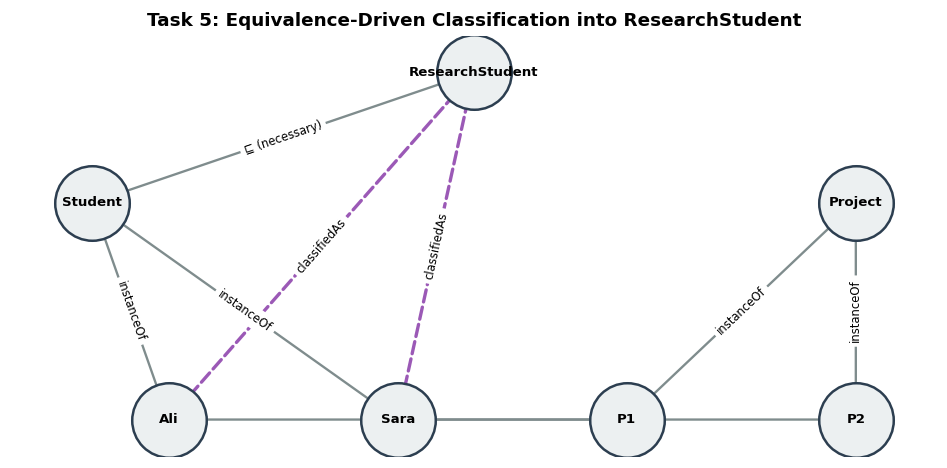

In [11]:
# Visualization of Task 5: Equivalence Classification Matching
plt.figure(figsize=(8, 4))
G5 = nx.DiGraph()

# Nodes
G5.add_node("Student", type="concept", color="#3498db")
G5.add_node("Project", type="concept", color="#3498db")
G5.add_node("ResearchStudent", type="defined", color="#9b59b6")
G5.add_node("Ali", type="ind", color="#2ecc71")
G5.add_node("Sara", type="ind", color="#2ecc71")
G5.add_node("P1", type="ind", color="#e67e22")
G5.add_node("P2", type="ind", color="#e67e22")

# Edges
G5.add_edge("ResearchStudent", "Student", label="⊑ (necessary)")
G5.add_edge("Ali", "Student", label="instanceOf")
G5.add_edge("Sara", "Student", label="instanceOf")
G5.add_edge("Ali", "P1", label="worksOn")
G5.add_edge("Sara", "P2", label="worksOn")
G5.add_edge("P1", "Project", label="instanceOf")
G5.add_edge("P2", "Project", label="instanceOf")
G5.add_edge("Ali", "ResearchStudent", label="classifiedAs", style="dashed")
G5.add_edge("Sara", "ResearchStudent", label="classifiedAs", style="dashed")

pos5 = {
    "ResearchStudent": (0.0, 1.0),
    "Student": (-1.0, 0.4),
    "Project": (1.0, 0.4),
    "Ali": (-0.8, -0.6),
    "Sara": (-0.2, -0.6),
    "P1": (0.4, -0.6),
    "P2": (1.0, -0.6)
}

nx.draw_networkx_nodes(G5, pos5, node_color="#ecf0f1", node_size=2000, edgecolors="#2c3e50", linewidths=1.5)
nx.draw_networkx_labels(G5, pos5, font_size=8, font_weight="bold")

solid_e = [(u, v) for u, v, d in G5.edges(data=True) if d.get("style") != "dashed"]
dashed_e = [(u, v) for u, v, d in G5.edges(data=True) if d.get("style") == "dashed"]

nx.draw_networkx_edges(G5, pos5, edgelist=solid_e, edge_color="#7f8c8d", width=1.4, arrows=True, arrowsize=12)
nx.draw_networkx_edges(G5, pos5, edgelist=dashed_e, edge_color="#9b59b6", width=2.0, style="dashed", arrows=True, arrowsize=14)

nx.draw_networkx_edge_labels(G5, pos5, edge_labels={(u, v): G5[u][v]["label"] for u, v in G5.edges()}, font_size=7)

plt.title("Task 5: Equivalence-Driven Classification into ResearchStudent", fontsize=11, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()

---
## Task 6 — Detect Inconsistency and Unsatisfiable Concepts

### Theoretical Context
In Description Logic, contradictions are formalized through disjointness axioms:
$$C \\sqcap D \\sqsubseteq \\bot \\quad (\\text{equivalent to } C \\sqsubseteq \\neg D)$$
which asserts that the intersection of concepts $C$ and $D$ must be empty in all interpretations ($C^{\\mathcal{I}} \\cap D^{\\mathcal{I}} = \\emptyset$).
It is crucial to distinguish two related but distinct logical conditions:
1. **Concept Unsatisfiability (TBox Incoherence):** A concept $C$ is unsatisfiable if $C^{\\mathcal{I}} = \\emptyset$ in every model $\\mathcal{I}$ of the TBox ($TBox \\models C \\sqsubseteq \\bot$). A TBox with unsatisfiable concepts can still be consistent, provided no individual is asserted to belong to the empty concept.
2. **Knowledge Base Inconsistency:** A knowledge base $\\mathcal{K} = \\langle \\mathcal{T}, \\mathcal{A} \\rangle$ is inconsistent if it has **no models** at all ($\\mathcal{K} \\models \\bot$). This occurs when an ABox assertion forces an individual to be an instance of an unsatisfiable concept.

### Implementation & Exercises
- **Exercise 6.1:** Add $\\text{Undergraduate} \\sqsubseteq \\text{Student}$, $\\text{Undergraduate}(\\text{Hina})$, $\\text{Employee}(\\text{Hina})$. Show the resulting clash.
- **Exercise 6.2:** Analyze $\\text{Student} \\sqsubseteq \\text{Person}$ and $\\text{Student} \\sqsubseteq \\neg \\text{Person}$. Is Student satisfiable? Could the TBox still have a model if Student has no instances?
- **Exercise 6.3:** Explain why adding $\\text{Student}(\\text{Ali})$ to that TBox makes the entire KB inconsistent.

In [12]:
# Disjointness constraints set: frozenset of mutually exclusive concept pairs
disjoint = {frozenset(("Student", "Employee"))}

def disjointness_clashes(memberships, disjoint_pairs):
    """Detects logical contradictions where an individual belongs to mutually disjoint classes."""
    by_individual = {}
    for individual, cls in memberships:
        by_individual.setdefault(individual, set()).add(cls)
    clashes = []
    for individual, classes in by_individual.items():
        for pair in disjoint_pairs:
            if pair <= classes:
                clashes.append((individual, tuple(sorted(pair))))
    return clashes

# Test on current valid closure
print("=== Baseline Disjointness Check ===")
base_clashes = disjointness_clashes(updated_closure, disjoint)
print("Current clashes in KB:", base_clashes)

# Test with temporary asserted Employee(Ali)
test_facts = set(concept_facts) | {("Ali", "Employee")}
test_closure, _ = infer_named_memberships(subclass, test_facts)
print("\n=== Temporary Clash Test: Asserting Employee(Ali) ===")
print("Clashes after Employee(Ali):", disjointness_clashes(test_closure, disjoint))

# --- Exercise 6.1: Add Undergraduate <= Student, Undergraduate(Hina), Employee(Hina) ---
subclass_ex61 = set(subclass) | {("Undergraduate", "Student")}
facts_ex61 = set(concept_facts) | {("Hina", "Undergraduate"), ("Hina", "Employee")}

closure_ex61, trace_ex61 = infer_named_memberships(subclass_ex61, facts_ex61)
clashes_ex61 = disjointness_clashes(closure_ex61, disjoint)

print("\n=== Exercise 6.1: Clash Diagnosis for Hina ===")
for step in trace_ex61:
    if step[0] == "Hina":
        print(f"  Trace for Hina: {step[1]} => {step[2]}")
print("Detected Disjointness Clashes:", clashes_ex61)

=== Baseline Disjointness Check ===
Current clashes in KB: []

=== Temporary Clash Test: Asserting Employee(Ali) ===
Clashes after Employee(Ali): [('Ali', ('Employee', 'Student'))]

=== Exercise 6.1: Clash Diagnosis for Hina ===
  Trace for Hina: Tutor => Student
  Trace for Hina: Student => Person
Detected Disjointness Clashes: [('Hina', ('Employee', 'Student'))]


### Task 6 — Explanation & Answers

#### Representation Meaning
Clash detection identifies formal logical contradictions. Under monotonic Description Logic, finding a clash means the knowledge base has reached an absurdity ($\\bot$). This alerts the knowledge engineer that the domain axioms and ground facts cannot simultaneously be true.

#### Exercise 6.1: Clash Analysis for Hina
- $\\text{Undergraduate}(\\text{Hina})$ is asserted.
- Axiom $\\text{Undergraduate} \\sqsubseteq \\text{Student}$ derives $\\text{Student}(\\text{Hina})$.
- $\\text{Employee}(\\text{Hina})$ is asserted.
- Hina now possesses both concepts: $\\{\\text{Student}, \\text{Employee}\\}$.
- Because $\\text{Student} \\sqcap \\text{Employee} \\sqsubseteq \\bot$, this triggers the clash: `('Hina', ('Employee', 'Student'))`.

#### Exercise 6.2: Concept Unsatisfiability Analysis
Consider the TBox axioms:
$$\\text{Student} \\sqsubseteq \\text{Person} \\quad \\text{and} \\quad \\text{Student} \\sqsubseteq \\neg \\text{Person}$$
1. **Is Student satisfiable?** **NO, Student is unsatisfiable ($\\text{Student} \\equiv \\bot$).**
   - For any individual $x \\in \\text{Student}^{\\mathcal{I}}$, it must satisfy $x \\in \\text{Person}^{\\mathcal{I}}$ and $x \\in (\\neg \\text{Person})^{\\mathcal{I}}$.
   - Since $(\\neg \\text{Person})^{\\mathcal{I}} = \\Delta^{\\mathcal{I}} \\setminus \\text{Person}^{\\mathcal{I}}$, this requires $x \\in \\text{Person}^{\\mathcal{I}} \\cap (\\Delta^{\\mathcal{I}} \\setminus \\text{Person}^{\\mathcal{I}}) = \\emptyset$, which is a direct mathematical contradiction.
   - Hence, $\\text{Student}^{\\mathcal{I}}$ must be empty in every valid model ($\\text{Student}^{\\mathcal{I}} = \\emptyset$).
2. **Can the TBox still have a model?** **YES.**
   - A TBox is consistent if there exists at least one model satisfying all axioms.
   - Consider the interpretation: $\\Delta^{\\mathcal{I}} = \\{d_1\\}$, $\\text{Person}^{\\mathcal{I}} = \\{d_1\\}$, and $\\text{Student}^{\\mathcal{I}} = \\emptyset$.
   - The axioms state: $\\emptyset \\subseteq \\{d_1\\}$ (True) and $\\emptyset \\subseteq \\emptyset$ (True).
   - Thus, the TBox has a valid model. An ontology with unsatisfiable concepts remains consistent as long as the unsatisfiable concepts remain empty.

#### Exercise 6.3: Why Adding `Student(Ali)` Makes the Entire KB Inconsistent
When $\\text{Student}(\\text{Ali})$ is added to the ABox:
- The ABox dictates that the concrete entity $\\text{Ali}^{\\mathcal{I}}$ must belong to $\\text{Student}^{\\mathcal{I}}$ ($\text{Ali}^{\mathcal{I}} \in \text{Student}^{\mathcal{I}}$).
- This forces $\\text{Student}^{\\mathcal{I}} \\neq \\emptyset$ (cardinality $\\ge 1$).
- However, as proven in Exercise 6.2, the TBox requires $\\text{Student}^{\\mathcal{I}} = \\emptyset$.
- There exists no interpretation $\\mathcal{I}$ that can simultaneously satisfy $\\text{Student}^{\\mathcal{I}} = \\emptyset$ and $\\text{Student}^{\\mathcal{I}} \\neq \\emptyset$.
- The set of valid models becomes empty: $\\text{Mod}(\\mathcal{K}) = \\emptyset$. Therefore, the **entire Knowledge Base becomes inconsistent**.

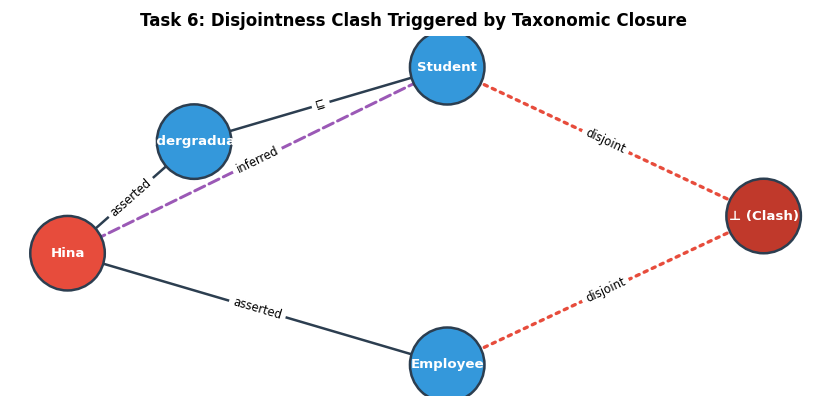

In [13]:
# Visualization of Task 6: Clash Detection Diagram
plt.figure(figsize=(7, 3.5))

G6 = nx.DiGraph()
G6.add_node("Undergraduate", color="#3498db")
G6.add_node("Student", color="#3498db")
G6.add_node("Employee", color="#3498db")
G6.add_node("Hina", color="#e74c3c")
G6.add_node("⊥ (Clash)", color="#c0392b")

G6.add_edge("Undergraduate", "Student", label="⊑")
G6.add_edge("Hina", "Undergraduate", label="asserted")
G6.add_edge("Hina", "Employee", label="asserted")
G6.add_edge("Hina", "Student", label="inferred", style="dashed")
G6.add_edge("Student", "⊥ (Clash)", label="disjoint", style="dotted")
G6.add_edge("Employee", "⊥ (Clash)", label="disjoint", style="dotted")

pos6 = {
    "Undergraduate": (-0.8, 0.4),
    "Student": (0.0, 0.8),
    "Employee": (0.0, -0.8),
    "Hina": (-1.2, -0.2),
    "⊥ (Clash)": (1.0, 0.0)
}

node_cols = ["#3498db", "#3498db", "#3498db", "#e74c3c", "#c0392b"]
nx.draw_networkx_nodes(G6, pos6, node_color=node_cols, node_size=2000, edgecolors="#2c3e50", linewidths=1.5)
nx.draw_networkx_labels(G6, pos6, font_size=8, font_color="white", font_weight="bold")

edges_solid = [(u, v) for u, v, d in G6.edges(data=True) if d.get("style") not in ["dashed", "dotted"]]
edges_dashed = [(u, v) for u, v, d in G6.edges(data=True) if d.get("style") == "dashed"]
edges_dotted = [(u, v) for u, v, d in G6.edges(data=True) if d.get("style") == "dotted"]

nx.draw_networkx_edges(G6, pos6, edgelist=edges_solid, edge_color="#2c3e50", width=1.5, arrows=True, arrowsize=12)
nx.draw_networkx_edges(G6, pos6, edgelist=edges_dashed, edge_color="#9b59b6", width=1.8, style="dashed", arrows=True, arrowsize=12)
nx.draw_networkx_edges(G6, pos6, edgelist=edges_dotted, edge_color="#e74c3c", width=2.0, style="dotted", arrows=True, arrowsize=12)

nx.draw_networkx_edge_labels(G6, pos6, edge_labels={(u, v): G6[u][v]["label"] for u, v in G6.edges()}, font_size=7)

plt.title("Task 6: Disjointness Clash Triggered by Taxonomic Closure", fontsize=10, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()

---
## Task 7 — Open-World Reasoning and Anonymous Witnesses

### Theoretical Context
The foundational philosophy of Description Logic and Web Ontologies differs fundamentally from relational databases and Prolog:
- **Closed-World Assumption (CWA):** Used in standard databases and logic programming. If a proposition cannot be proven true from known facts, it is assumed to be **false** (negation-as-failure).
- **Open-World Assumption (OWA):** Used in Description Logic. An unasserted fact is simply **unknown**. Knowledge is assumed to be incomplete unless an explicit axiom or negative assertion refutes it. Entailment ($\mathcal{K} \models \alpha$) requires that $\alpha$ hold in **every** model of $\mathcal{K}$.
- **Absence of Unique Name Assumption (UNA):** In standard DL/OWL, two distinct syntactical names ($a$ and $b$) can map to the exact same physical domain entity ($a^{\mathcal{I}} = b^{\mathcal{I}}$) unless explicitly asserted to be pairwise distinct via $\text{DifferentIndividuals}(a, b)$.

### Implementation & Exercises
- **Exercise 7.1:** Given $\\text{Student} \\sqsubseteq \\exists \\text{enrolledIn}.\\text{Course}$ and $\\text{Student}(\\text{Ali})$, explain what is entailed and why $\\text{enrolledIn}(\\text{Ali}, \\text{CS101})$ is not necessarily entailed.
- **Exercise 7.2:** State whether `Ali` and `Student123` must denote different objects. What additional assertion is needed?
- **Exercise 7.3:** Explain why an empty role-fact list is not evidence for $\\neg \\exists \\text{enrolledIn}.\\text{Course}(\\text{Ali})$.

In [14]:
def query_named_membership(individual, cls, inferred):
    """Evaluates membership query under Open-World Assumption (ENTAILED vs UNKNOWN)."""
    return "ENTAILED" if (individual, cls) in inferred else "UNKNOWN"

def query_role(subject, role, obj, facts):
    """Evaluates role assertion query under Open-World Assumption (ENTAILED vs UNKNOWN)."""
    return "ENTAILED" if (subject, role, obj) in facts else "UNKNOWN"

print("=== Task 7: Open-World Query Answering ===")
print("Query 1: Sara is a Person?               ", query_named_membership("Sara", "Person", updated_closure))
print("Query 2: Ali is a Professor?            ", query_named_membership("Ali", "Professor", updated_closure))
print("Query 3: Sara enrolled in CS101?        ", query_role("Sara", "enrolledIn", "CS101", role_facts))
print("Query 4: Ali enrolled in CS101?         ", query_role("Ali", "enrolledIn", "CS101", role_facts))
print("Query 5: DrAhmed teaches CS101?         ", query_role("DrAhmed", "teaches", "CS101", role_facts))
print("Query 6: DrAhmed teaches AI201?         ", query_role("DrAhmed", "teaches", "AI201", role_facts))

=== Task 7: Open-World Query Answering ===
Query 1: Sara is a Person?                ENTAILED
Query 2: Ali is a Professor?             UNKNOWN
Query 3: Sara enrolled in CS101?         UNKNOWN
Query 4: Ali enrolled in CS101?          ENTAILED
Query 5: DrAhmed teaches CS101?          ENTAILED
Query 6: DrAhmed teaches AI201?          UNKNOWN


### Task 7 — Explanation & Answers

#### Representation Meaning
In Description Logic, query evaluation distinguishes between provable truth and epistemic uncertainty. The response `UNKNOWN` reflects that the current knowledge base neither entails the assertion nor entails its negation; both possibilities remain open across different models.

#### Exercise 7.1: Entailment vs. Non-Entailment of Role Assertions
Given the knowledge base $\\mathcal{K} = \\{\\text{Student} \\sqsubseteq \\exists \\text{enrolledIn}.\\text{Course}, \\text{Student}(\\text{Ali})\\}$:
- **What IS entailed:** It is strictly entailed that Ali is enrolled in *some* course: $\\mathcal{K} \\models \\exists \\text{enrolledIn}.\\text{Course}(\\text{Ali})$. Every valid model of $\\mathcal{K}$ must contain a course successor for Ali.
- **Why $\\text{enrolledIn}(\\text{Ali}, \\text{CS101})$ is NOT entailed:** An assertion is entailed if and only if it holds in **all** models. There exist infinitely many valid models of $\\mathcal{K}$ where Ali is enrolled in `AI201`, or `MATH100`, or an anonymous course entity $w$, but is **not** enrolled in `CS101`. Because there exists at least one model where `enrolledIn(Ali, CS101)` is false, it is not logically entailed. Its truth value is **UNKNOWN**.

#### Exercise 7.2: Absence of Unique Name Assumption (UNA)
- **Do `Ali` and `Student123` necessarily denote different objects?** **NO.**
- In Description Logic and OWL, the Unique Name Assumption is **not** made by default. Different names are treated as syntactic identifiers that may co-refer to the same physical domain individual (i.e., $\\text{Ali}^{\\mathcal{I}} = \\text{Student123}^{\\mathcal{I}}$ is permissible).
- **Required Assertion:** To enforce that they represent distinct individuals, one must explicitly declare:
  $$\\text{DifferentIndividuals}(\\text{Ali}, \\text{Student123}) \\quad \\text{or} \\quad \\text{Ali} \\neq \\text{Student123}$$

#### Exercise 7.3: Why an Empty Role-Fact List is Not Evidence for Negation
Under the Open-World Assumption, the absence of a statement in an ABox indicates an **absence of information**, not the **information of absence**.
- In a closed-world database, if a table has no rows linking Ali to a course, the system infers $\\neg \\text{enrolledIn}(\\text{Ali}, c)$.
- In Description Logic, knowledge is assumed to be incomplete. An empty list of role facts simply means that no enrollments have been recorded yet. There are valid models where Ali has enrollments that have not been stated.
- To prove $\\neg \\exists \\text{enrolledIn}.\\text{Course}(\\text{Ali})$, the ontology must contain an explicit constraint or negative assertion such as $\\text{Ali} : \\forall \\text{enrolledIn}.\\bot$ or $\\text{Student} \\sqsubseteq \\neg \\exists \\text{enrolledIn}.\\text{Course}$.

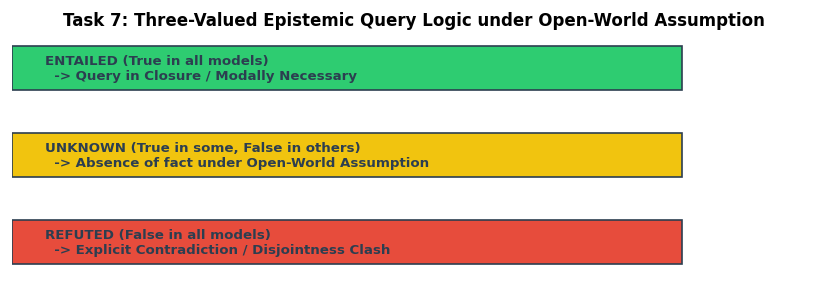

In [15]:
# Visualization of Task 7: Epistemic Three-Valued Logic
plt.figure(figsize=(7, 2.5))
categories = ["ENTAILED (True in all models)", "UNKNOWN (True in some, False in others)", "REFUTED (False in all models)"]
colors = ["#2ecc71", "#f1c40f", "#e74c3c"]
y_pos = [2, 1, 0]

plt.barh(y_pos, [1, 1, 1], color=colors, height=0.5, edgecolor="#2c3e50")
for i, txt in enumerate(["Query in Closure / Modally Necessary", "Absence of fact under Open-World Assumption", "Explicit Contradiction / Disjointness Clash"]):
    plt.text(0.05, y_pos[i], f"{categories[i]}\n  -> {txt}", va="center", color="#2c3e50", fontweight="bold", fontsize=8)

plt.xlim(0, 1.2)
plt.axis("off")
plt.title("Task 7: Three-Valued Epistemic Query Logic under Open-World Assumption", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

---
## Task 8 — Mini University Ontology Challenge: Academic Library & Resource Management

### Scenario Overview
We design a compact, cohesive Description Logic ontology for a university library resource management system.

### Specifications & Explicit Labeling
#### 1. Concepts ($\ge 5$):
- `LibraryItem` (TBox)
- `Book` (TBox)
- `JournalArticle` (TBox)
- `Patron` (TBox)
- `FacultyPatron` (TBox)
- `UndergradPatron` (TBox)
- `ActiveBorrower` (TBox, Defined Concept)
- `RestrictedBorrower` (TBox)

#### 2. Roles ($\ge 2$):
- `borrows` (TBox): relates a Patron to a LibraryItem
- `authoredBy` (TBox): relates a LibraryItem to a Patron/Author

#### 3. Named Individuals ($\ge 4$):
- `Alice`, `Bob`, `Charlie` (ABox Patrons)
- `Book_AI101`, `Journal_DL2026` (ABox LibraryItems)

#### 4. Subclass Axioms ($\ge 3$):
1. $\\text{Book} \\sqsubseteq \\text{LibraryItem}$ (TBox)
2. $\\text{JournalArticle} \\sqsubseteq \\text{LibraryItem}$ (TBox)
3. $\\text{FacultyPatron} \\sqsubseteq \\text{Patron}$ (TBox)
4. $\\text{UndergradPatron} \\sqsubseteq \\text{Patron}$ (TBox)

#### 5. Equivalence Definition containing $\\sqcap$ and $\\exists$:
$$\\text{ActiveBorrower} \\equiv \\text{Patron} \\sqcap \\exists \\text{borrows}.\\text{LibraryItem}$$

#### 6. Universal Restriction:
$$\\text{RestrictedBorrower} \\sqsubseteq \\forall \\text{borrows}.\\text{Book}$$
(Every restricted borrower may only borrow books, never journals or other materials).

#### 7. Assertions ($\ge 5$ Class, $\ge 3$ Role):
- Class Assertions (ABox):
  - $\\text{FacultyPatron}(\\text{Alice})$
  - $\\text{UndergradPatron}(\\text{Bob})$
  - $\\text{Patron}(\\text{Charlie})$
  - $\\text{Book}(\\text{Book_AI101})$
  - $\\text{JournalArticle}(\\text{Journal_DL2026})$
- Role Assertions (ABox):
  - $\\text{borrows}(\\text{Alice}, \\text{Book_AI101})$
  - $\\text{borrows}(\\text{Bob}, \\text{Journal_DL2026})$
  - $\\text{borrows}(\\text{Charlie}, \\text{Book_AI101})$

In [16]:
# === Task 8 Implementation: Academic Library Ontology ===

# 1. TBox Subclass Axioms
lib_subclass = {
    ("Book", "LibraryItem"),
    ("JournalArticle", "LibraryItem"),
    ("FacultyPatron", "Patron"),
    ("UndergradPatron", "Patron")
}

# 2. ABox Class Assertions
lib_concept_facts = {
    ("Alice", "FacultyPatron"),
    ("Bob", "UndergradPatron"),
    ("Charlie", "Patron"),
    ("Book_AI101", "Book"),
    ("Journal_DL2026", "JournalArticle")
}

# 3. ABox Role Assertions
lib_role_facts = {
    ("Alice", "borrows", "Book_AI101"),
    ("Bob", "borrows", "Journal_DL2026"),
    ("Charlie", "borrows", "Book_AI101")
}

# 4. Compute Taxonomic Deductive Closure
lib_closure, lib_trace = infer_named_memberships(lib_subclass, lib_concept_facts)

print("=== Derived Memberships Trace (Step-by-Step Explanation) ===")
for step in lib_trace:
    print(f"  Step: Individual '{step[0]}' has asserted class '{step[1]}'")
    print(f"        Axiom '{step[1]} ⊑ {step[2]}' infers => {step[2]}('{step[0]}')\n")

# Verify the two required derivations
print("Derivation 1 - Patron(Alice):       ", ("Alice", "Patron") in lib_closure)
print("Derivation 2 - LibraryItem(Book_AI101):", ("Book_AI101", "LibraryItem") in lib_closure)

# 5. Defined Concept Classification: ActiveBorrower ≡ Patron ⊓ ∃borrows.LibraryItem
items_in_closure = {x for x, cls in lib_closure if cls == "LibraryItem"}
borrowing_items = {x for x, role, y in lib_role_facts if role == "borrows" and y in items_in_closure}
patrons_in_closure = {x for x, cls in lib_closure if cls == "Patron"}

active_borrowers = patrons_in_closure & borrowing_items
print("\n=== Classification of ActiveBorrower via Equivalence ===")
print("ActiveBorrowers recognized:", sorted(active_borrowers))

# 6. Disjointness Constraint & Inconsistency Diagnosis
lib_disjoint = {
    frozenset(("Book", "JournalArticle")),
    frozenset(("FacultyPatron", "UndergradPatron"))
}

print("\n=== Consistent Baseline Check ===")
print("Baseline Library Clashes:", disjointness_clashes(lib_closure, lib_disjoint))

# Construct an Inconsistent ABox
inconsistent_facts = set(lib_concept_facts) | {("Alice", "UndergradPatron")}
inconsistent_closure, _ = infer_named_memberships(lib_subclass, inconsistent_facts)
detected_clashes = disjointness_clashes(inconsistent_closure, lib_disjoint)

print("\n=== Inconsistent ABox Clashes ===")
print("Clashes detected after asserting UndergradPatron(Alice):", detected_clashes)

# 7. Open-World Query Answering
print("\n=== Open-World Reasoning Queries ===")
q_entailed = query_named_membership("Alice", "Patron", lib_closure)
q_unknown_mem = query_named_membership("Charlie", "FacultyPatron", lib_closure)
q_unknown_role = query_role("Alice", "borrows", "Journal_DL2026", lib_role_facts)

print(f"Query 1 [Entailed]: Patron(Alice)                      => {q_entailed}")
print(f"Query 2 [Unknown]:  FacultyPatron(Charlie)             => {q_unknown_mem}")
print(f"Query 3 [Unknown]:  borrows(Alice, Journal_DL2026)     => {q_unknown_role}")

=== Derived Memberships Trace (Step-by-Step Explanation) ===
  Step: Individual 'Book_AI101' has asserted class 'Book'
        Axiom 'Book ⊑ LibraryItem' infers => LibraryItem('Book_AI101')

  Step: Individual 'Journal_DL2026' has asserted class 'JournalArticle'
        Axiom 'JournalArticle ⊑ LibraryItem' infers => LibraryItem('Journal_DL2026')

  Step: Individual 'Bob' has asserted class 'UndergradPatron'
        Axiom 'UndergradPatron ⊑ Patron' infers => Patron('Bob')

  Step: Individual 'Alice' has asserted class 'FacultyPatron'
        Axiom 'FacultyPatron ⊑ Patron' infers => Patron('Alice')

Derivation 1 - Patron(Alice):        True
Derivation 2 - LibraryItem(Book_AI101): True

=== Classification of ActiveBorrower via Equivalence ===
ActiveBorrowers recognized: ['Alice', 'Bob', 'Charlie']

=== Consistent Baseline Check ===
Baseline Library Clashes: []

=== Inconsistent ABox Clashes ===
Clashes detected after asserting UndergradPatron(Alice): [('Alice', ('FacultyPatron', 'Undergra

### Task 8 — Explanation & Reasoning Comparison

#### Step-by-Step Derivation Explanations
1. **Derivation 1: $\\text{Patron}(\\text{Alice})$**
   - Asserted fact: $\\text{FacultyPatron}(\\text{Alice})$.
   - TBox axiom: $\\text{FacultyPatron} \\sqsubseteq \\text{Patron}$.
   - Explanation: Since every FacultyPatron is a subclass of Patron, Alice upwardly inherits membership in `Patron`.
2. **Derivation 2: $\\text{LibraryItem}(\\text{Book_AI101})$**
   - Asserted fact: $\\text{Book}(\\text{Book_AI101})$.
   - TBox axiom: $\\text{Book} \\sqsubseteq \\text{LibraryItem}$.
   - Explanation: Since Book is a subclass of LibraryItem, the individual `Book_AI101` is entailed to be a `LibraryItem`.
3. **Equivalence Classification: $\\text{ActiveBorrower}$**
   - Criteria: $\\text{ActiveBorrower} \\equiv \\text{Patron} \\sqcap \\exists \\text{borrows}.\\text{LibraryItem}$.
   - Alice, Bob, and Charlie are all members of `Patron` (via closure or assertion) and each borrows an individual proven to be a `LibraryItem`. Hence, all three are classified as `ActiveBorrower`.

#### Disjointness Inconsistency Analysis
- **Axiom:** $\\text{FacultyPatron} \\sqcap \\text{UndergradPatron} \\sqsubseteq \\bot$.
- **Inconsistent Fact Introduced:** $\\text{UndergradPatron}(\\text{Alice})$.
- **Diagnosis:** Alice now simultaneously possesses $\\text{FacultyPatron}$ and $\\text{UndergradPatron}$. Because these two concepts are declared mutually exclusive, their intersection is empty ($\\bot$). This creates an immediate clash: `('Alice', ('FacultyPatron', 'UndergradPatron'))`, rendering the ABox inconsistent.

#### Open-World Querying Analysis
- `Patron(Alice)` is **ENTAILED** because it is provably true in all models via taxonomic closure.
- `FacultyPatron(Charlie)` is **UNKNOWN**. Charlie is asserted as a general `Patron`. Under open-world semantics, Charlie may or may not be a faculty patron; the knowledge base does not contain enough information to entail either conclusion.
- `borrows(Alice, Journal_DL2026)` is **UNKNOWN**. The absence of this role assertion in the ABox does not imply that Alice does not borrow the journal.

---

### In-Depth Comparison: Python Helper vs. Complete DL Reasoner

| Dimension | Our Python Teaching Helper | Complete DL Reasoner (e.g., HermiT, Pellet, FaCT++) |
| :--- | :--- | :--- |
| **Logical Expressivity** | Lightweight propositional subset + named subclass forward chaining + basic set-matching. | Full expressive Description Logics (e.g., $\\mathcal{SROIQ}(\\mathcal{D})$, OWL 2 DL). |
| **Reasoning Algorithm** | Rule-based forward-chaining over explicit ground facts (fixed-point iteration). | Sound and complete **Tableau / Hypertableau** decision procedures. |
| **Existential Quantifiers ($\\exists R.C$)** | Looks up existing, named ground individuals in the ABox. Cannot invent new entities. | Generates **anonymous existential witness trees** with blocking mechanisms to ensure termination. |
| **Disjunctive Reasoning ($\\sqcup$)** | Evaluates only union over explicit models; cannot reason about uncommitted disjunctions. | Performs **branching search**: tests each disjunct ($A \\sqcup B$) independently to verify entailment. |
| **Negation & Complements ($\\neg$)** | Evaluates set complement relative to a closed finite domain $\\Delta^{\\mathcal{I}}$. | Normalizes complex expressions into **Negation Normal Form (NNF)** across infinite models. |
| **General Concept Inclusions (GCIs)** | Limited to atomic concept inclusions ($A \\sqsubseteq B$). | Handles arbitrary GCIs ($C_1 \\sqcap \\exists R.C_2 \\sqsubseteq D_1 \\sqcup \\forall S.D_2$). |
| **Open-World Soundness & Completeness** | Incomplete: reports UNKNOWN when a fact is unasserted, missing indirect deductions. | Provably **sound and complete**: explores the space of all possible models; if a clash occurs in all branches, negation is refuted and entailment is proved. |

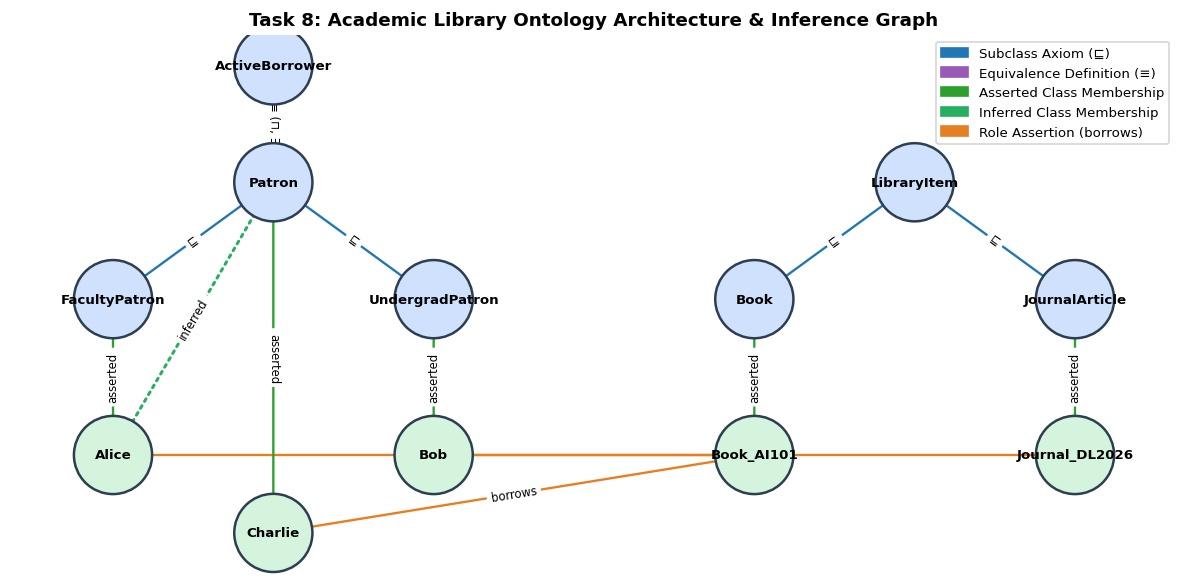

In [17]:
# Visualization of Task 8: Complete Academic Library Ontology Graph
plt.figure(figsize=(10, 5))
G8 = nx.DiGraph()

# Add TBox concepts
concepts_8 = ["LibraryItem", "Book", "JournalArticle", "Patron", "FacultyPatron", "UndergradPatron", "ActiveBorrower"]
for c in concepts_8:
    G8.add_node(c, ntype="concept")

# Add ABox individuals
inds_8 = ["Alice", "Bob", "Charlie", "Book_AI101", "Journal_DL2026"]
for i in inds_8:
    G8.add_node(i, ntype="individual")

# Subclass edges
for child, parent in lib_subclass:
    G8.add_edge(child, parent, label="⊑", color="#1f77b4", style="solid")

# Equivalence
G8.add_edge("ActiveBorrower", "Patron", label="≡ (⊓, ∃)", color="#9b59b6", style="dashed")

# Inferred instance-of
G8.add_edge("Alice", "FacultyPatron", label="asserted", color="#2ca02c", style="solid")
G8.add_edge("Alice", "Patron", label="inferred", color="#27ae60", style="dotted")
G8.add_edge("Bob", "UndergradPatron", label="asserted", color="#2ca02c", style="solid")
G8.add_edge("Charlie", "Patron", label="asserted", color="#2ca02c", style="solid")
G8.add_edge("Book_AI101", "Book", label="asserted", color="#2ca02c", style="solid")
G8.add_edge("Journal_DL2026", "JournalArticle", label="asserted", color="#2ca02c", style="solid")

# Roles
for s, r, o in lib_role_facts:
    G8.add_edge(s, o, label=r, color="#e67e22", style="solid")

pos8 = {
    "LibraryItem": (0.8, 1.0),
    "Book": (0.4, 0.4),
    "JournalArticle": (1.2, 0.4),
    "Patron": (-0.8, 1.0),
    "FacultyPatron": (-1.2, 0.4),
    "UndergradPatron": (-0.4, 0.4),
    "ActiveBorrower": (-0.8, 1.6),
    "Alice": (-1.2, -0.4),
    "Bob": (-0.4, -0.4),
    "Charlie": (-0.8, -0.8),
    "Book_AI101": (0.4, -0.4),
    "Journal_DL2026": (1.2, -0.4)
}

node_cols8 = ["#d0e1fd" if G8.nodes[n].get("ntype") == "concept" else "#d4f4dd" for n in G8.nodes()]
nx.draw_networkx_nodes(G8, pos8, node_color=node_cols8, node_size=2200, edgecolors="#2c3e50", linewidths=1.5)
nx.draw_networkx_labels(G8, pos8, font_size=8, font_weight="bold")

edges_solid = [(u, v) for u, v, d in G8.edges(data=True) if d.get("style") == "solid"]
edges_dashed = [(u, v) for u, v, d in G8.edges(data=True) if d.get("style") == "dashed"]
edges_dotted = [(u, v) for u, v, d in G8.edges(data=True) if d.get("style") == "dotted"]

nx.draw_networkx_edges(G8, pos8, edgelist=edges_solid, edge_color=[G8[u][v]["color"] for u, v in edges_solid], width=1.4, arrows=True, arrowsize=12)
nx.draw_networkx_edges(G8, pos8, edgelist=edges_dashed, edge_color="#9b59b6", width=1.8, style="dashed", arrows=True, arrowsize=12)
nx.draw_networkx_edges(G8, pos8, edgelist=edges_dotted, edge_color="#27ae60", width=1.8, style="dotted", arrows=True, arrowsize=12)

nx.draw_networkx_edge_labels(G8, pos8, edge_labels={(u, v): G8[u][v]["label"] for u, v in G8.edges()}, font_size=7)

legend_patches8 = [
    mpatches.Patch(color='#1f77b4', label='Subclass Axiom (⊑)'),
    mpatches.Patch(color='#9b59b6', label='Equivalence Definition (≡)'),
    mpatches.Patch(color='#2ca02c', label='Asserted Class Membership'),
    mpatches.Patch(color='#27ae60', label='Inferred Class Membership'),
    mpatches.Patch(color='#e67e22', label='Role Assertion (borrows)')
]
plt.legend(handles=legend_patches8, loc="upper right", frameon=True, fontsize=8)
plt.title("Task 8: Academic Library Ontology Architecture & Inference Graph", fontsize=11, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()

---
## Post-Lab Discussion & Comprehensive Answers

### 1. Distinguishing Concepts, Roles, Individuals, TBox, and ABox
- **Concepts** correspond to unary predicates representing sets of domain objects.
- **Roles** correspond to binary predicates representing directed relationships between objects.
- **Individuals** correspond to domain constants referring to specific named objects.
- **TBox statements** are intensional schema rules (e.g., $C \\sqsubseteq D, C \\equiv D$) that constrain all possible worlds.
- **ABox statements** are extensional ground assertions ($C(a), R(a, b)$) describing a specific concrete state of affairs.

### 2. Semantics of Universal vs. Existential Restrictions
- $\\exists R.C$ requires the existence of *at least one* $R$-successor belonging to $C$. If an individual has no $R$-successors, it fails the existential restriction.
- $\\forall R.C$ requires that *if* any $R$-successors exist, they *must* belong to $C$. Individuals with zero $R$-successors satisfy this condition **vacuously** because the premise of the implication is false.

### 3. Concept Unsatisfiability vs. Knowledge Base Inconsistency
- **Concept Unsatisfiability ($C \\sqsubseteq \\bot$):** A concept is logically contradictory and can have no instances in any model. However, the TBox remains consistent if $C^{\\mathcal{I}} = \\emptyset$.
- **Knowledge Base Inconsistency ($\mathcal{K} \models \bot$):** The entire knowledge base possesses zero models. This occurs when an individual in the ABox is asserted or inferred to belong to an unsatisfiable concept.

### 4. Open-World Assumption (OWA) vs. Closed-World Assumption (CWA)
Under OWA, missing facts represent incomplete knowledge rather than falsity. A query evaluates to `UNKNOWN` unless a formal contradiction refutes all countermodels. This is vital for the semantic web and decentralized knowledge bases where no single authority possesses complete information.

### 5. Absence of Unique Name Assumption (UNA)
Unlike relational databases, distinct syntactical names in DL do not automatically denote distinct individuals. To enforce identity distinction, explicit `DifferentIndividuals` axioms must be stated.